In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import seaborn as sns
import math

def round_sig(x, sig=3):
    if x == 0:
        return 0
    return round(x, sig - int(math.floor(math.log10(abs(x)))) - 1)

In [9]:
mpl.style.use('default')
mpl.rcParams['axes.linewidth'] = 7  # set the value globally
mpl.rcParams['xtick.major.size'] = 24
mpl.rcParams['xtick.major.width'] = 7
mpl.rcParams['xtick.minor.size'] = 16
mpl.rcParams['xtick.minor.width'] = 7
mpl.rcParams['ytick.major.size'] = 24
mpl.rcParams['ytick.major.width'] = 7
mpl.rcParams['ytick.labelsize'] = 75
mpl.rcParams['xtick.labelsize'] = 75
mpl.rcParams['ytick.minor.size'] = 16
mpl.rcParams['ytick.minor.width'] = 7
mpl.rcParams['font.size'] = 55
mpl.rcParams['font.sans-serif'] = 'Arial'
mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['svg.fonttype'] = 'none'

In [75]:
basal_cell_df = pd.read_csv(r"basal_cell_df_example.csv")

Text(0.5, 0, 'Unique Experiment Well')

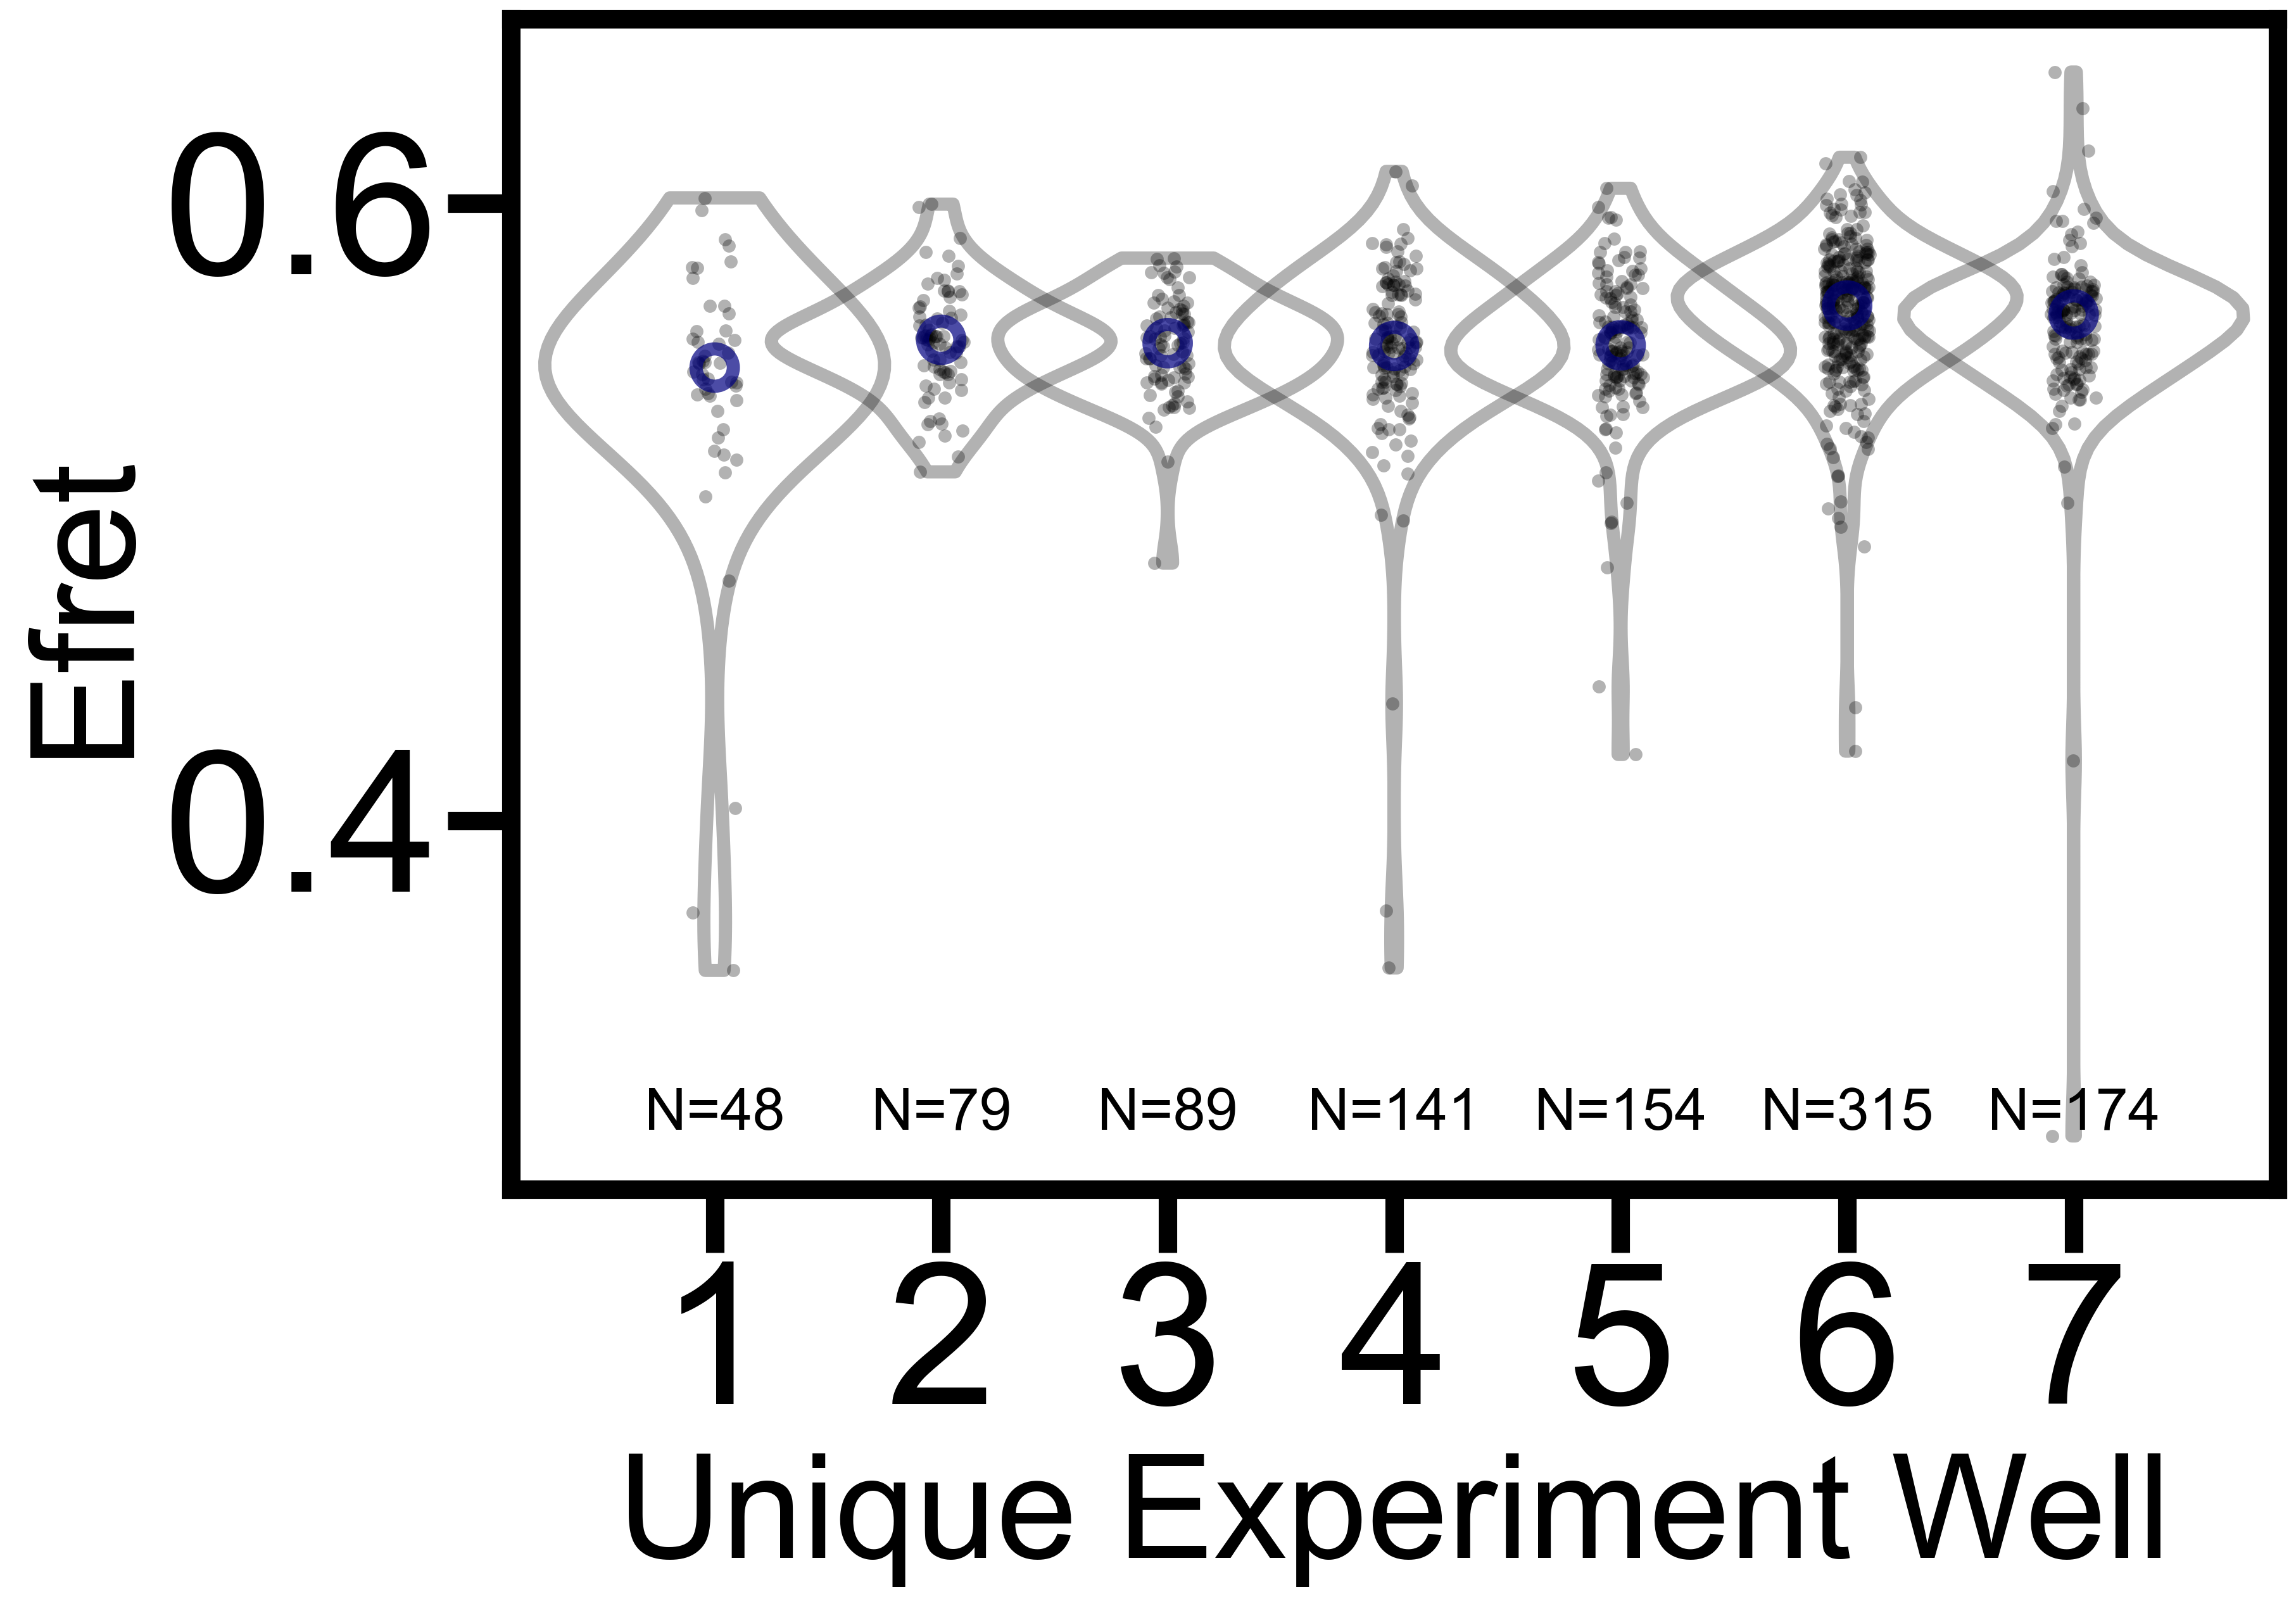

In [11]:

fig, ax = plt.subplots(figsize=(12, 8))
generator = basal_cell_df.groupby(['date', 'well'])
posit=0
for i, df_container in enumerate(generator):
    iter_df = df_container[1]
    if len(iter_df) <25:
        continue
    
    posit += 1
    violins = ax.violinplot(iter_df['Efret'], [posit-1], widths =1.5, showextrema=False, showmedians=False, showmeans=False)

    for pc in violins['bodies']:
        pc.set_facecolor('None')
        pc.set_edgecolor('k')
        pc.set_aplha=0.6
        pc.set_linewidth(5)

    median = iter_df['Efret'].median()
    ax.scatter(posit-1, median, s=200, edgecolor='navy', linewidth=5, color ='white', zorder=3, alpha=0.7, facecolors='none')
    
    sns.stripplot(iter_df, x= posit, y = 'Efret', color='k', alpha=0.3, zorder=1)
    
    ax.text(posit-1, 0.3, s='N='+ str(len(iter_df)), fontsize=22, ha='center')

ax.set_xlim(-0.9, 6.9)
ax.set_xlabel('Unique Experiment Well')

#plt.savefig(r'example_violin.svg', format='svg', bbox_inches='tight')

[Text(0, 0, 'T1')]

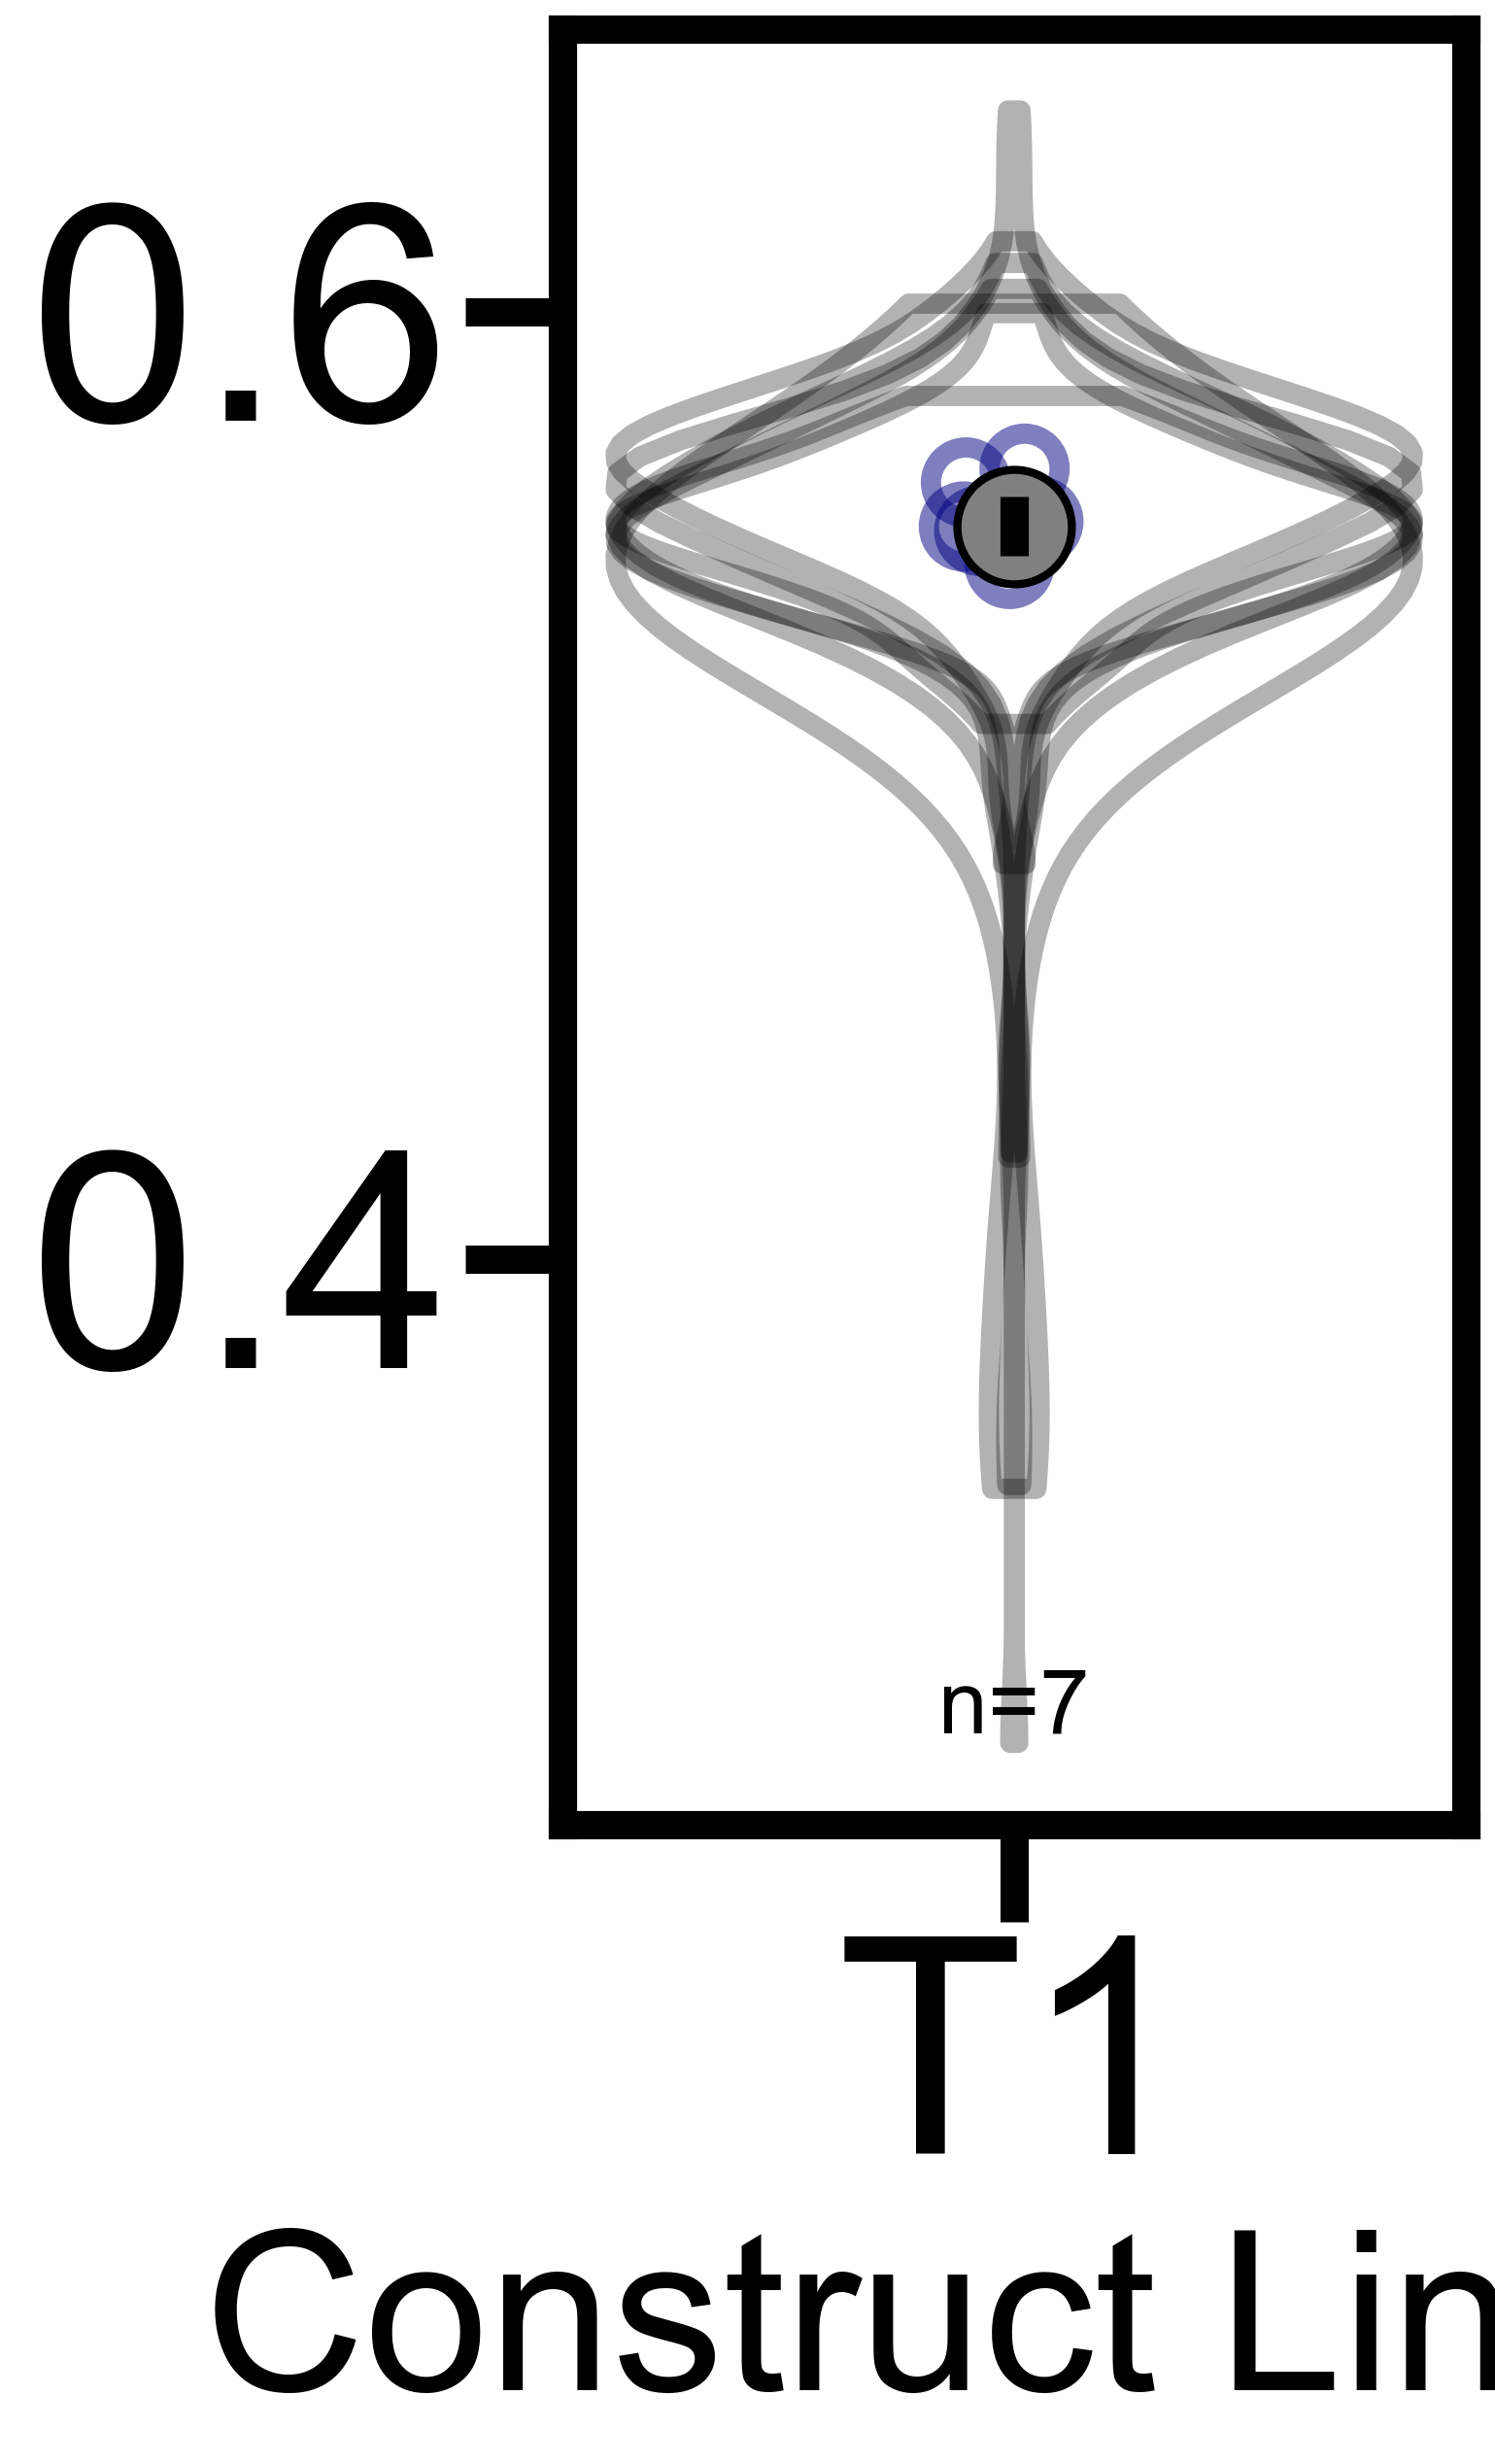

In [12]:
fig, ax = plt.subplots(figsize=(4, 8))
generator = basal_cell_df.groupby(['date', 'well'])
posit=0

median_list = []
for i, df_container in enumerate(generator):
    iter_df = df_container[1]
    
    posit = 1
    violins = ax.violinplot(iter_df['Efret'], [posit-1], widths =1.5, showextrema=False, showmedians=False, showmeans=False)

    for pc in violins['bodies']:
        pc.set_facecolor('None')
        pc.set_edgecolor('k')
        pc.set_aplha=0.6
        pc.set_linewidth(5)

    median = iter_df['Efret'].median()
    median_list.append(median)
    
    
    x_positions =np.random.uniform(-0.10, 0.10, size=1)
    ax.scatter(x_positions, median, s=300, edgecolor='navy', linewidth=5, color ='white', zorder=3, alpha=0.5,facecolors='none')
    
    #sns.stripplot(iter_df, x= posit, y = 'Efret', color='k', alpha=0.3, zorder=1)
ax.errorbar(posit-1, y=np.median(median_list), yerr=np.std(median_list), elinewidth=7, zorder=4, ecolor='k')    
ax.scatter(posit-1, y = np.median(median_list), s=800, color='gray', zorder=3, edgecolor='k', linewidth=2)
ax.text(posit-1, 0.3, s='n='+ str(len(median_list)), fontsize=22, ha='center')
ax.set_xlim(-0.85, 0.85)
ax.set_xlabel('Construct Linker')
ax.set_xticks([0])
ax.set_xticklabels(['T1'])
#plt.savefig(r'example_overlay_violin.svg', format='svg', bbox_inches='tight')

In [62]:
tiles_cell_df = pd.read_csv(r"full_tile_violinplots.csv")

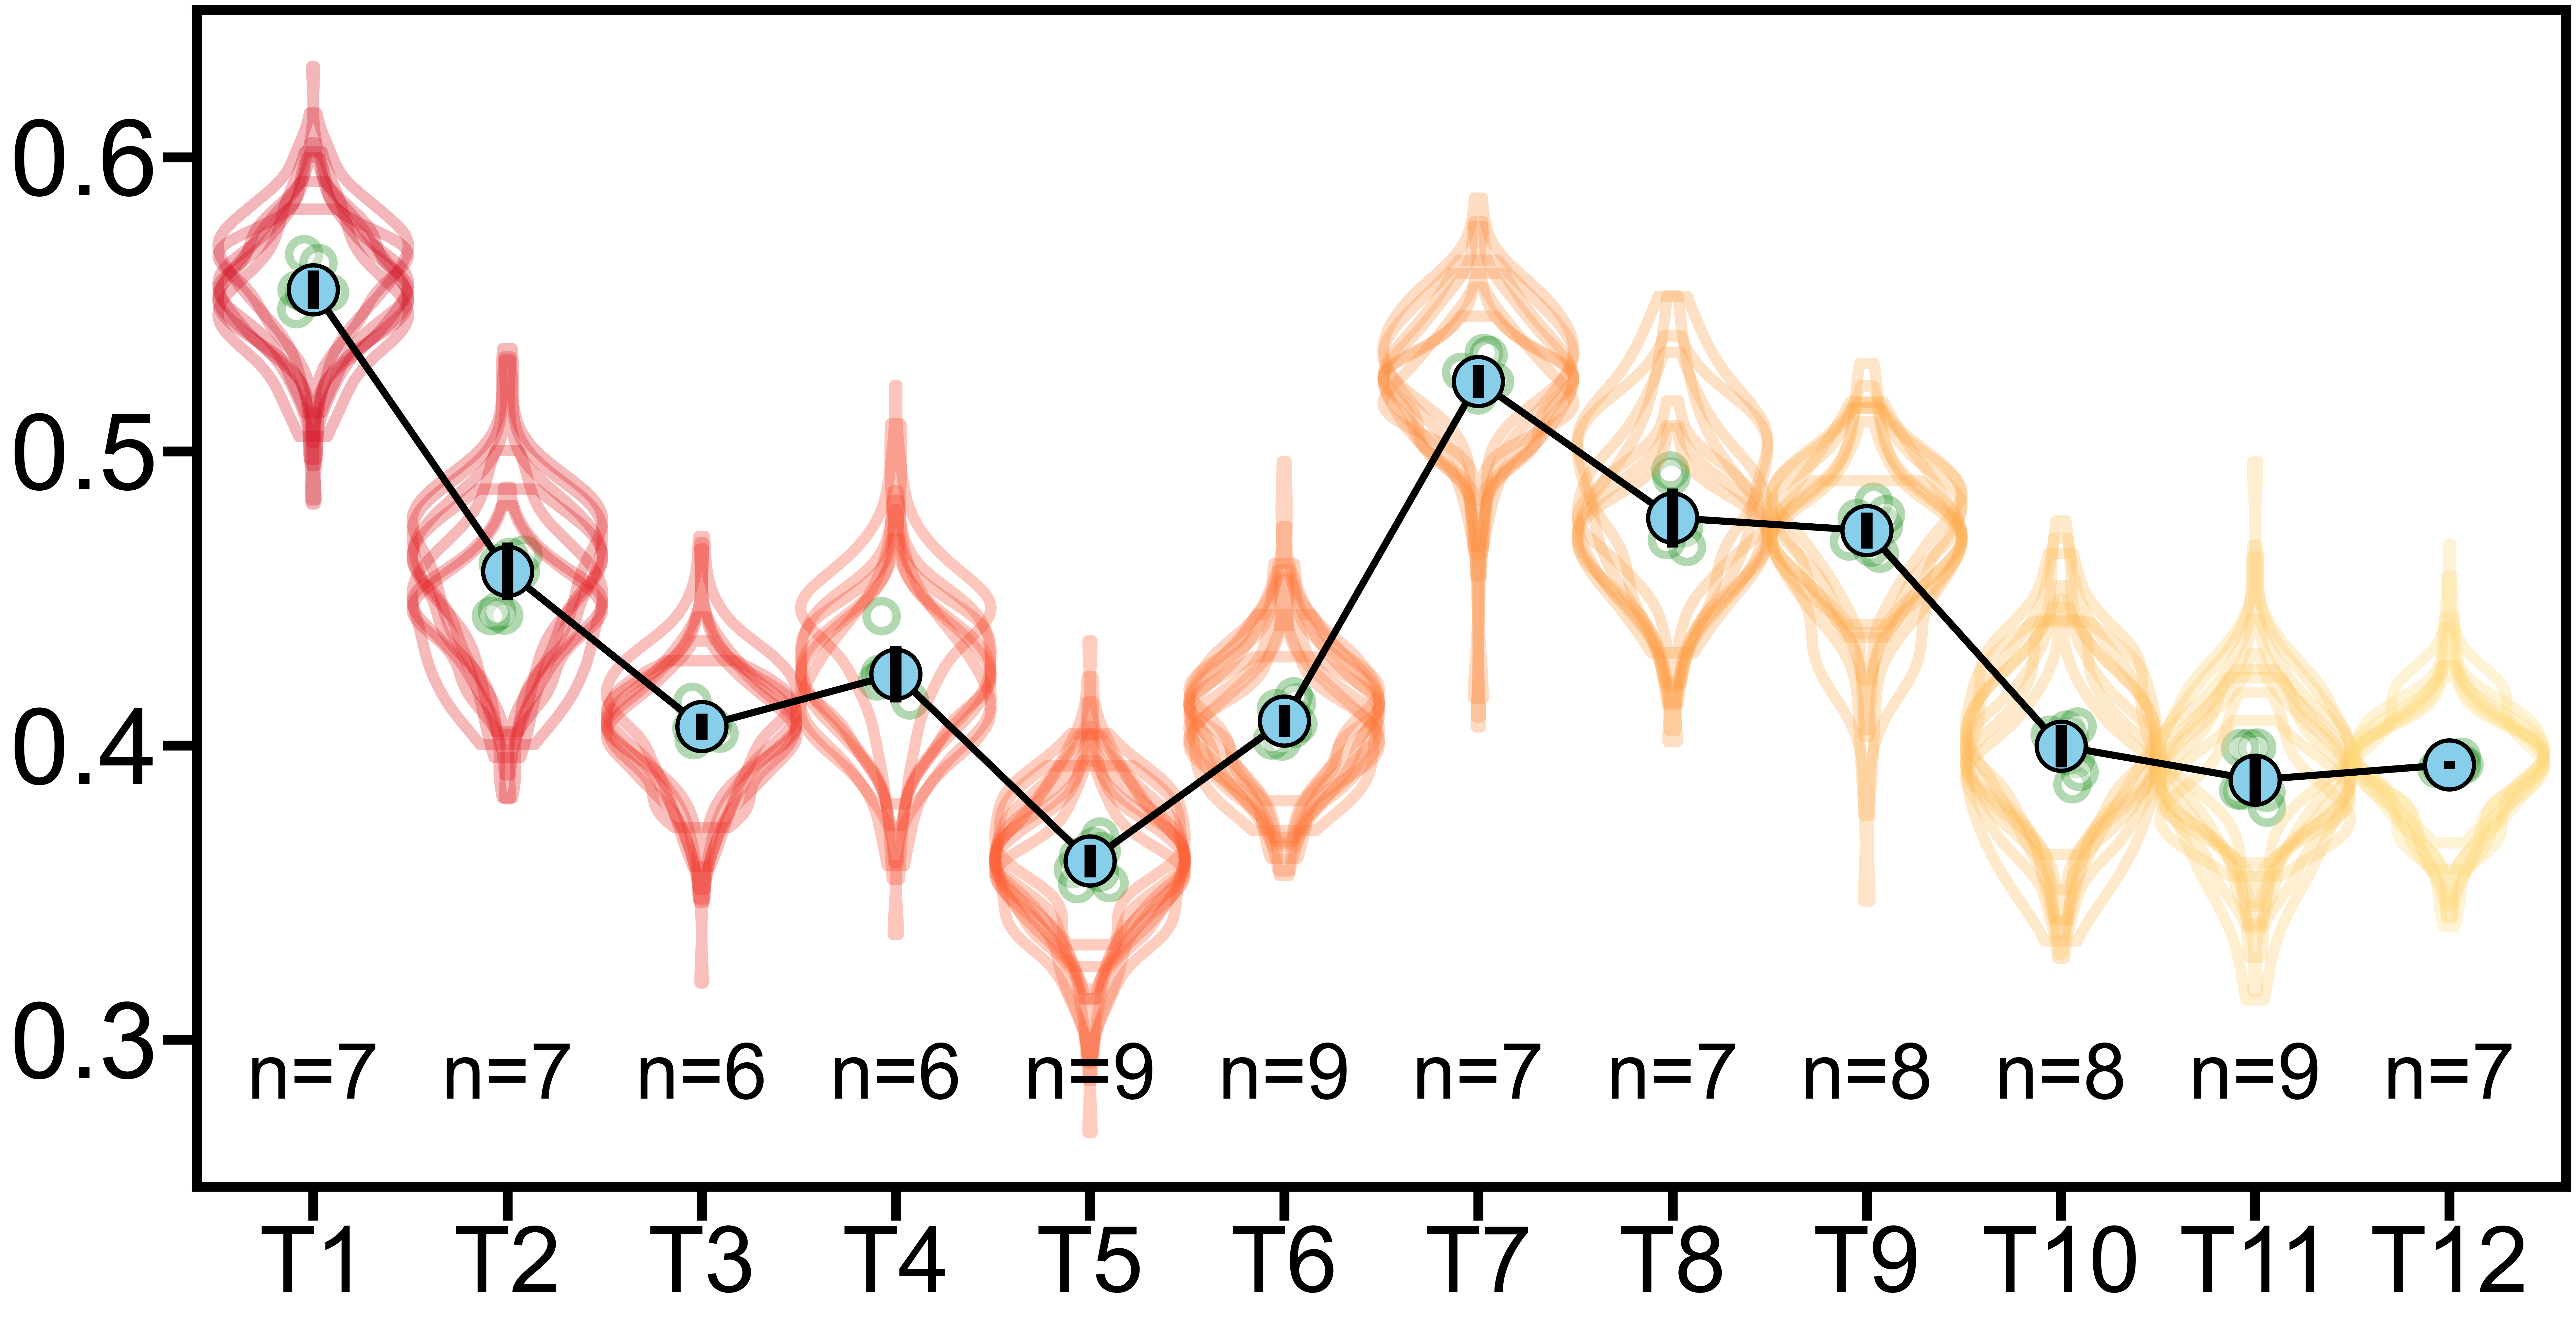

In [64]:
N=12

fig, ax = plt.subplots(figsize=(30, 15))
colors = iter(plt.cycler("color", plt.cm.YlOrRd(np.linspace(0.8, 0.25, N))))

uni_construct = tiles_cell_df['construct'].unique()
construct_array = sorted(np.array(uni_construct).astype(int))


func_1 = np.vectorize(lambda x : ((x-1) *20 + 1))
func_2 = np.vectorize(lambda x : ((x) * 20 + 44))

pos_1 = func_1(construct_array)
pos_2 = func_2(construct_array)

xlabel_list = []
for i, pos in enumerate(pos_1):
    '''
    start = pos_1[i]
    end = pos_2[i]
    sequence = f'{start}-{end}'
    '''
    sequence = f'T{i+1}'
    xlabel_list.append(sequence)
construct_list= []
ef_list =[]
std_list = []

basal_generator = tiles_cell_df.groupby(['construct', 'date', 'well'], observed=True)
medians = basal_generator['Efret'].median()
experiment_medians_list = []
for index, df_container in enumerate(basal_generator):
    if index == 0:
        #select first color
        color = next(colors)['color']
        #initiate positions for plots
        position = 1
        #set current_construct to change positions
        current_construct = df_container[0][0]
        #initiate list for x tick label axis
        x_tick_list = [current_construct]
        
        # set up statistics to plot
        current_medians = medians[current_construct]
        experiment_median = current_medians.median()
        experiment_std = current_medians.std()
        
        
        plot_stats = False
        
    if current_construct != df_container[0][0]:
        color = next(colors)['color']
        position += 1
        current_construct = df_container[0][0]
        x_tick_list.append(current_construct)
        current_medians = medians[current_construct]
        experiment_median = current_medians.median()
        experiment_std = current_medians.std()
        plot_stats = False
    if not plot_stats:
        ax.scatter(y=experiment_median, x=[position], zorder=3, color='skyblue', s=1200, edgecolor='k', linewidth=3)
        std_list.append(experiment_std)
        ef_list.append(experiment_median)
        construct_list.append(current_construct)
        x_positions = position + np.random.uniform(-0.1, 0.1, size=len(current_medians))
        ax.scatter(y = current_medians, x=  x_positions, s=450, edgecolor='green', linewidth=6, c='white', alpha=0.3)
        #ax.text(0.68, position, s='n='+str(len(current_medians)), ha ='center')
        ax.errorbar(x=[position], y=experiment_median, yerr=experiment_std, color='k', elinewidth=8, zorder=3)
        #ax.scatter(x=[position], y=experiment_median, zorder=3, color='gray', s=350 )
        #ax.scatter(x = [position] * len(current_medians), y= current_medians, s=300, edgecolor='navy', linewidth=6, c='white')
        ax.text(position, 0.28, s='n='+str(len(current_medians)), ha ='center')
        experiment_medians_list.append(experiment_median)
        plot_stats = True
    basal_df = df_container[1]
    data = basal_df['Efret']
    violins = ax.violinplot(data, [position], widths=0.98, showextrema=False, showmedians=False, showmeans=False)

    for pc in violins['bodies']:
        pc.set_facecolor('None')
        pc.set_edgecolor(color)
        pc.set_linewidth(8)
        pc.set_alpha(0.3)

x_pos = [r+1 for r in range(12)]
y_pos = medians.tolist()
ax.plot(x_pos, experiment_medians_list, c='k', linewidth=5)

ax.set_xticks(np.arange(1, len(x_tick_list)+1, 1))

ax.set_xticklabels(xlabel_list, fontsize=65)    
#ax.set_ylabel('Efret', fontsize='xx-large')
#ax.set_xlabel('Construct', fontsize='xx-large')
ax.set_xlim([0.4, 12.6])
ax.set_ylim([0.25, 0.65])
ax.set_yticks([0.3, 0.4, 0.5, 0.6])
#plt.savefig(r'basal_dim_violins_wNewData.svg', format='svg', bbox_inches='tight')
plt.show()

In [68]:
comp_df = pd.read_pickle(r"Ef_to_Re_comp.pkl")
comp_df.head()

,tile,R_end_to_end,Ef,std
0,T1,60.796135,0.554731,0.006780
1,T2,65.010506,0.459215,0.009589
2,T3,64.288742,0.406402,0.004187
3,T4,62.981426,0.423920,0.011630
4,T5,62.705284,0.360718,0.005390


In [69]:
#Calculate error
from scipy import stats

n = 10000 
rho_sim = np.zeros(n) 
p_sim = np.zeros(n)

center = np.array(comp_df['Ef'])
y_error = np.array(comp_df['std'])

correlation = np.array(comp_df['R_end_to_end'])

for i in range(n):
    #Generate random weights using mean weights with measurement error
    fret_sim = np.random.normal(center,y_error, 12)
    
    #Calculate correlation coefficient and p-value
    rho_sim[i],p_sim[i] = stats.pearsonr(correlation, fret_sim)

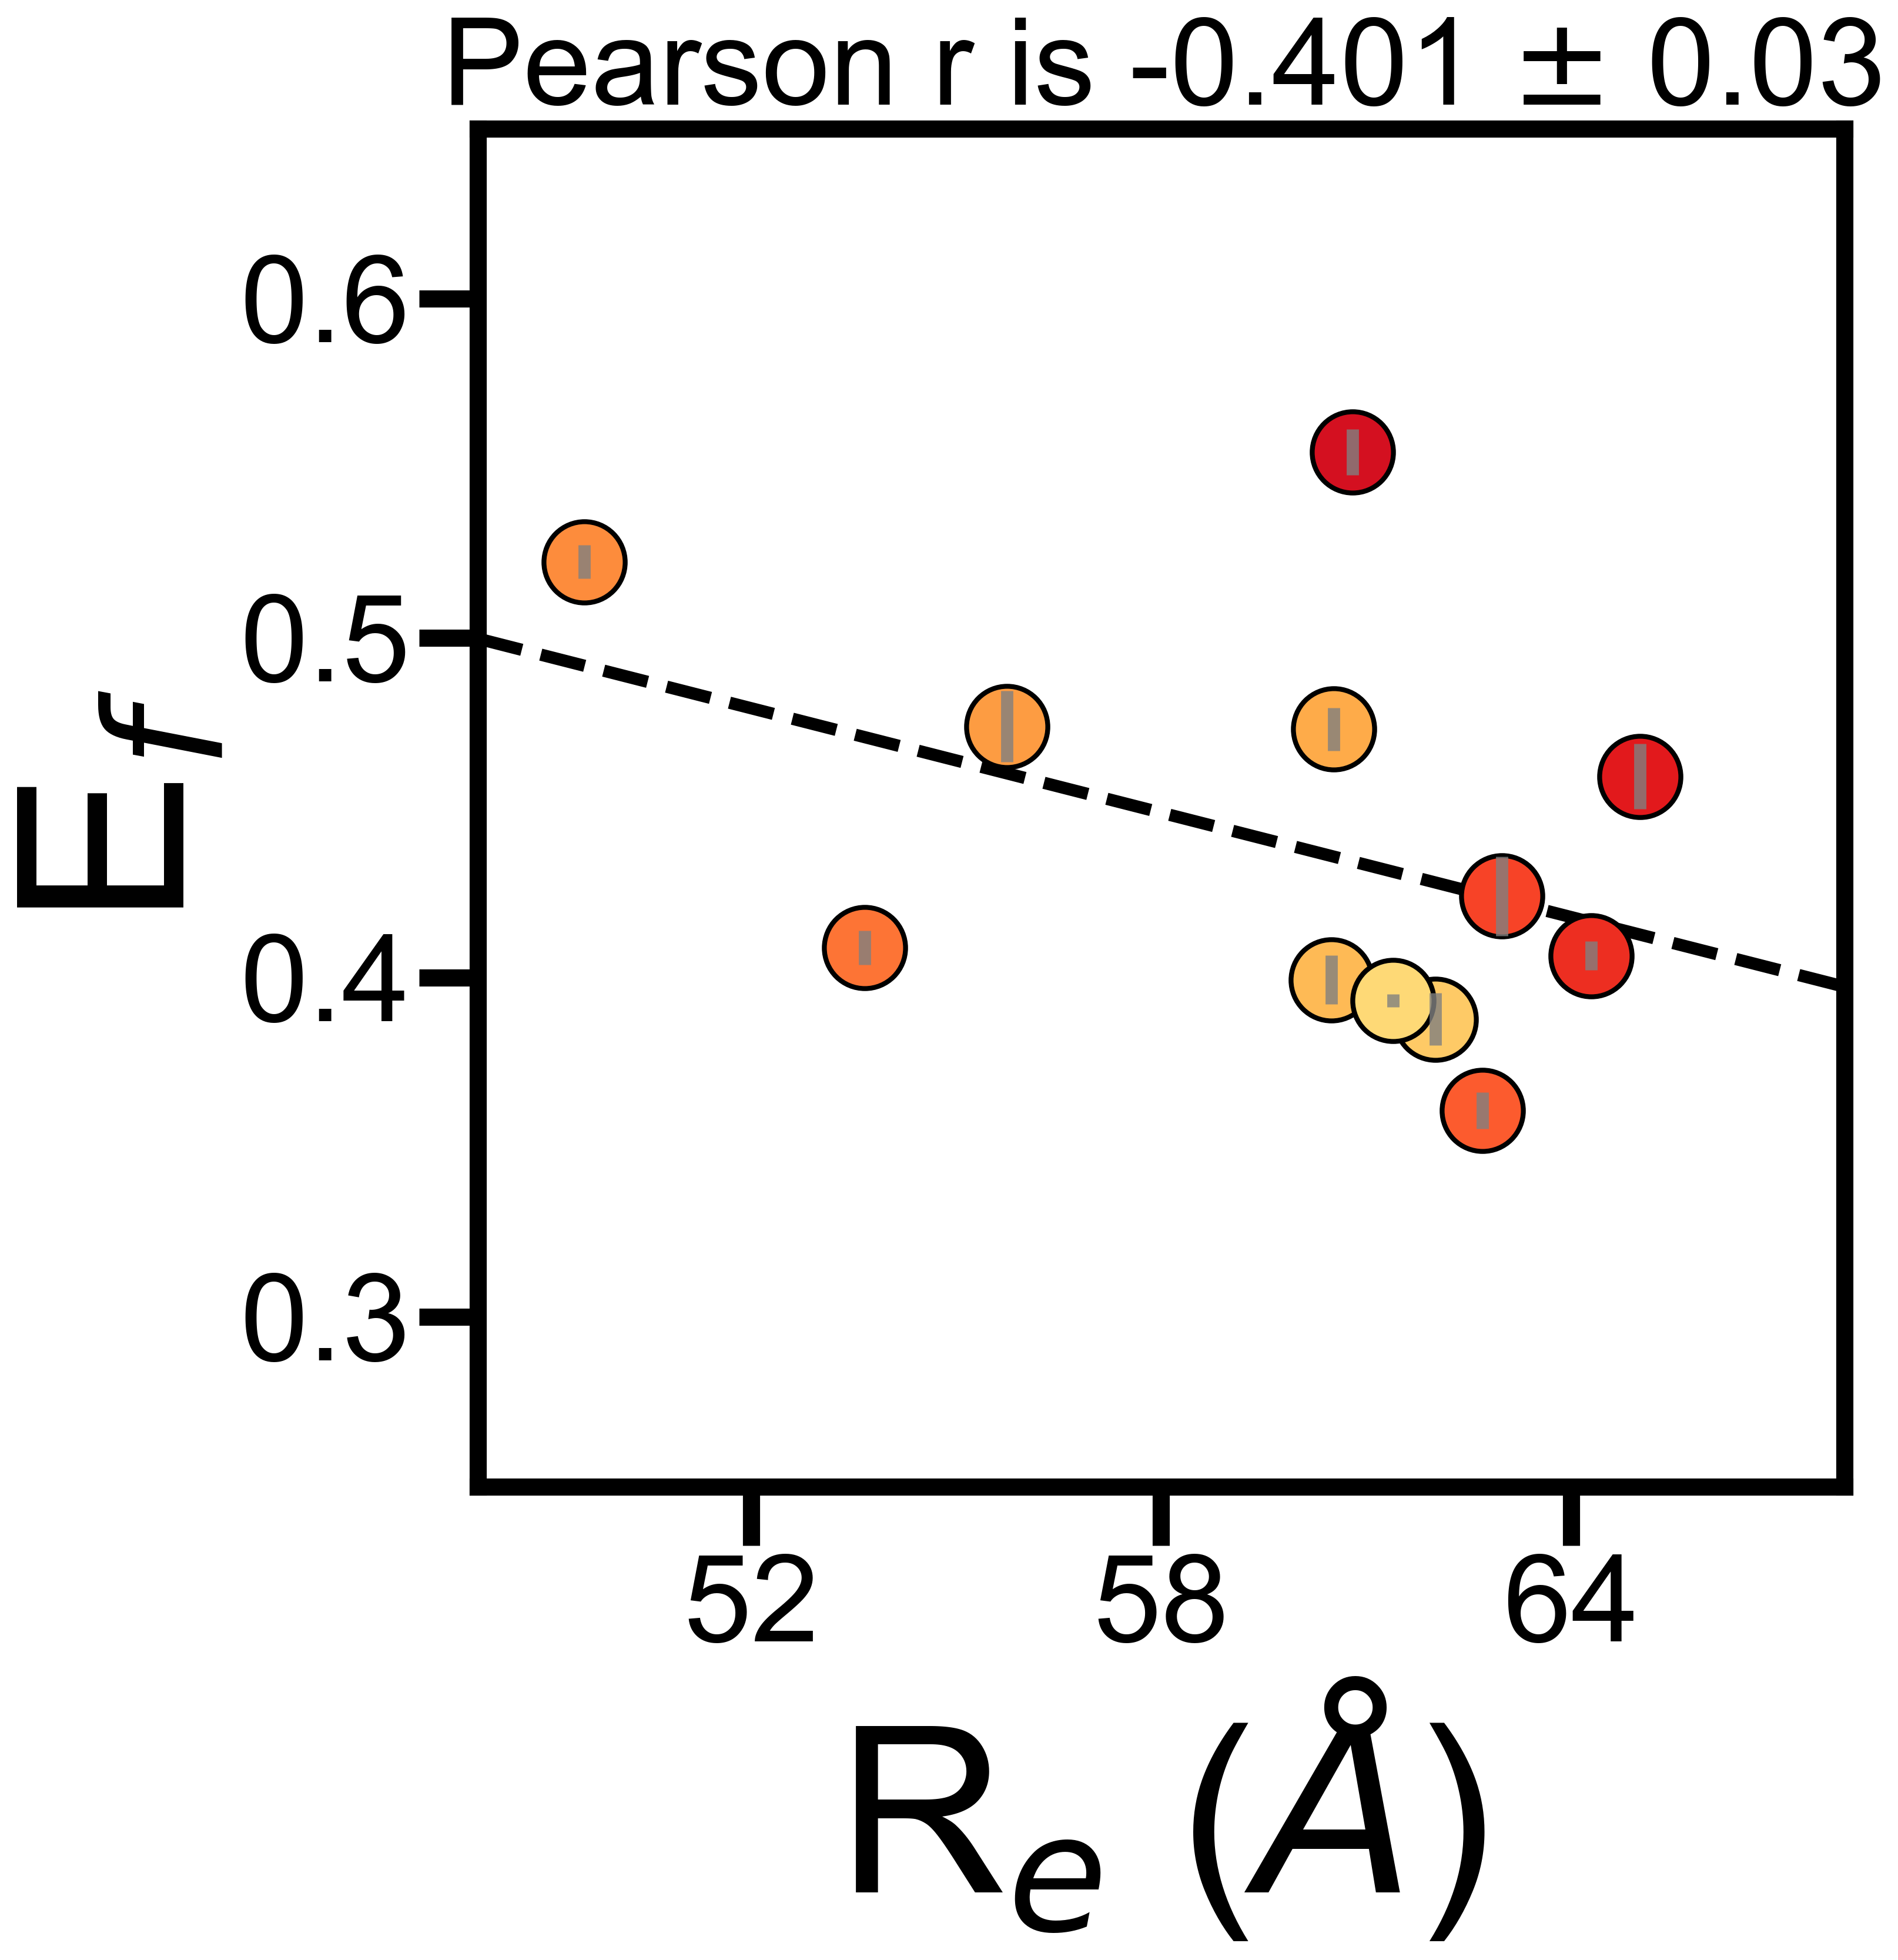

In [70]:
median_r = np.median(rho_sim)
std_r = np.std(rho_sim)
anstrom = "\u00C5"
N=12
plt.rcParams["axes.prop_cycle"] = plt.cycler("color", plt.cm.YlOrRd(np.linspace(0.8, 0.25, N)))

x= correlation
y= center
error = y_error
x_label = f'R$_e$ (${anstrom}$)'

fig, ax  = plt.subplots(figsize=(10, 10))
mpl.rcParams['figure.dpi'] = 300
res = stats.linregress(x, y)
ax.set_xlim([48, 68])
ax.set_ylim([0.25,0.65])
temp_x = np.array([48, 68])
ax.plot(temp_x, res.intercept + res.slope*temp_x, 'k--', linewidth=5)
for i, b, e in zip(x, y, error):
    ax.scatter(x=i, y=b, edgecolors='k', s=1100, zorder=3, linewidths=2) 
    ax.errorbar(x=i, y=b, yerr=e, c='gray', alpha=0.8, linewidth=5, zorder=4)

r_squared = res.rvalue **2
ax.tick_params(axis='both', which='major', labelsize=23)
ax.set_title(f"Pearson r is {round_sig(median_r, 3)} $\pm$ {round_sig(std_r, 1)}", fontsize=50)

yticks = [0.3, 0.4, 0.5, 0.6]
xticks = [52, 58, 64]
#xticks = [0.0, 0.6, 1.2]

ax.set_yticks(yticks)
ax.set_xticks(xticks)

tick_fontsize = 50
ax.set_yticklabels(yticks, fontsize=tick_fontsize)
ax.set_xticklabels(xticks, fontsize=tick_fontsize)

y_column = "E$_f$"
ax.set_ylabel(y_column, fontsize='xx-large')
ax.set_xlabel(x_label, fontsize='xx-large')

plt.savefig(r'Efret_comparison_to_Re.svg' , format='svg', bbox_inches='tight')

In [78]:
disorder_tile = pd.read_csv("disorder_Ef_df.csv")
disorder_tile.head()

,Unnamed: 0,tile,Average_disordered,std_score,Ef,std
0,0,T1,0.402252,0.278378,0.554731,0.006780
1,1,T2,0.545578,0.107360,0.459215,0.009589
2,2,T3,0.661677,0.156521,0.406402,0.004187
3,3,T4,0.677130,0.154716,0.423920,0.011630
4,4,T5,0.796212,0.072572,0.360718,0.005390


In [71]:
#Calculate error
n = 10000 
rho_sim = np.zeros(n) 
p_sim = np.zeros(n)

center = np.array(disorder_tile['Ef'])
y_error = np.array(disorder_tile['std'])

correlation = np.array(disorder_tile['Average_disordered'])
#correlation_error = np.array(disorder_tile['std_score'])
for i in range(n):
    #Generate random weights using mean weights with measurement error
    fret_sim = np.random.normal(center,y_error, 12)
    #disorder_sim = np.random.normal(correlation ,correlation_error, 12)
    #Calculate correlation coefficient and p-value
    rho_sim[i],p_sim[i] = stats.pearsonr(correlation, fret_sim)

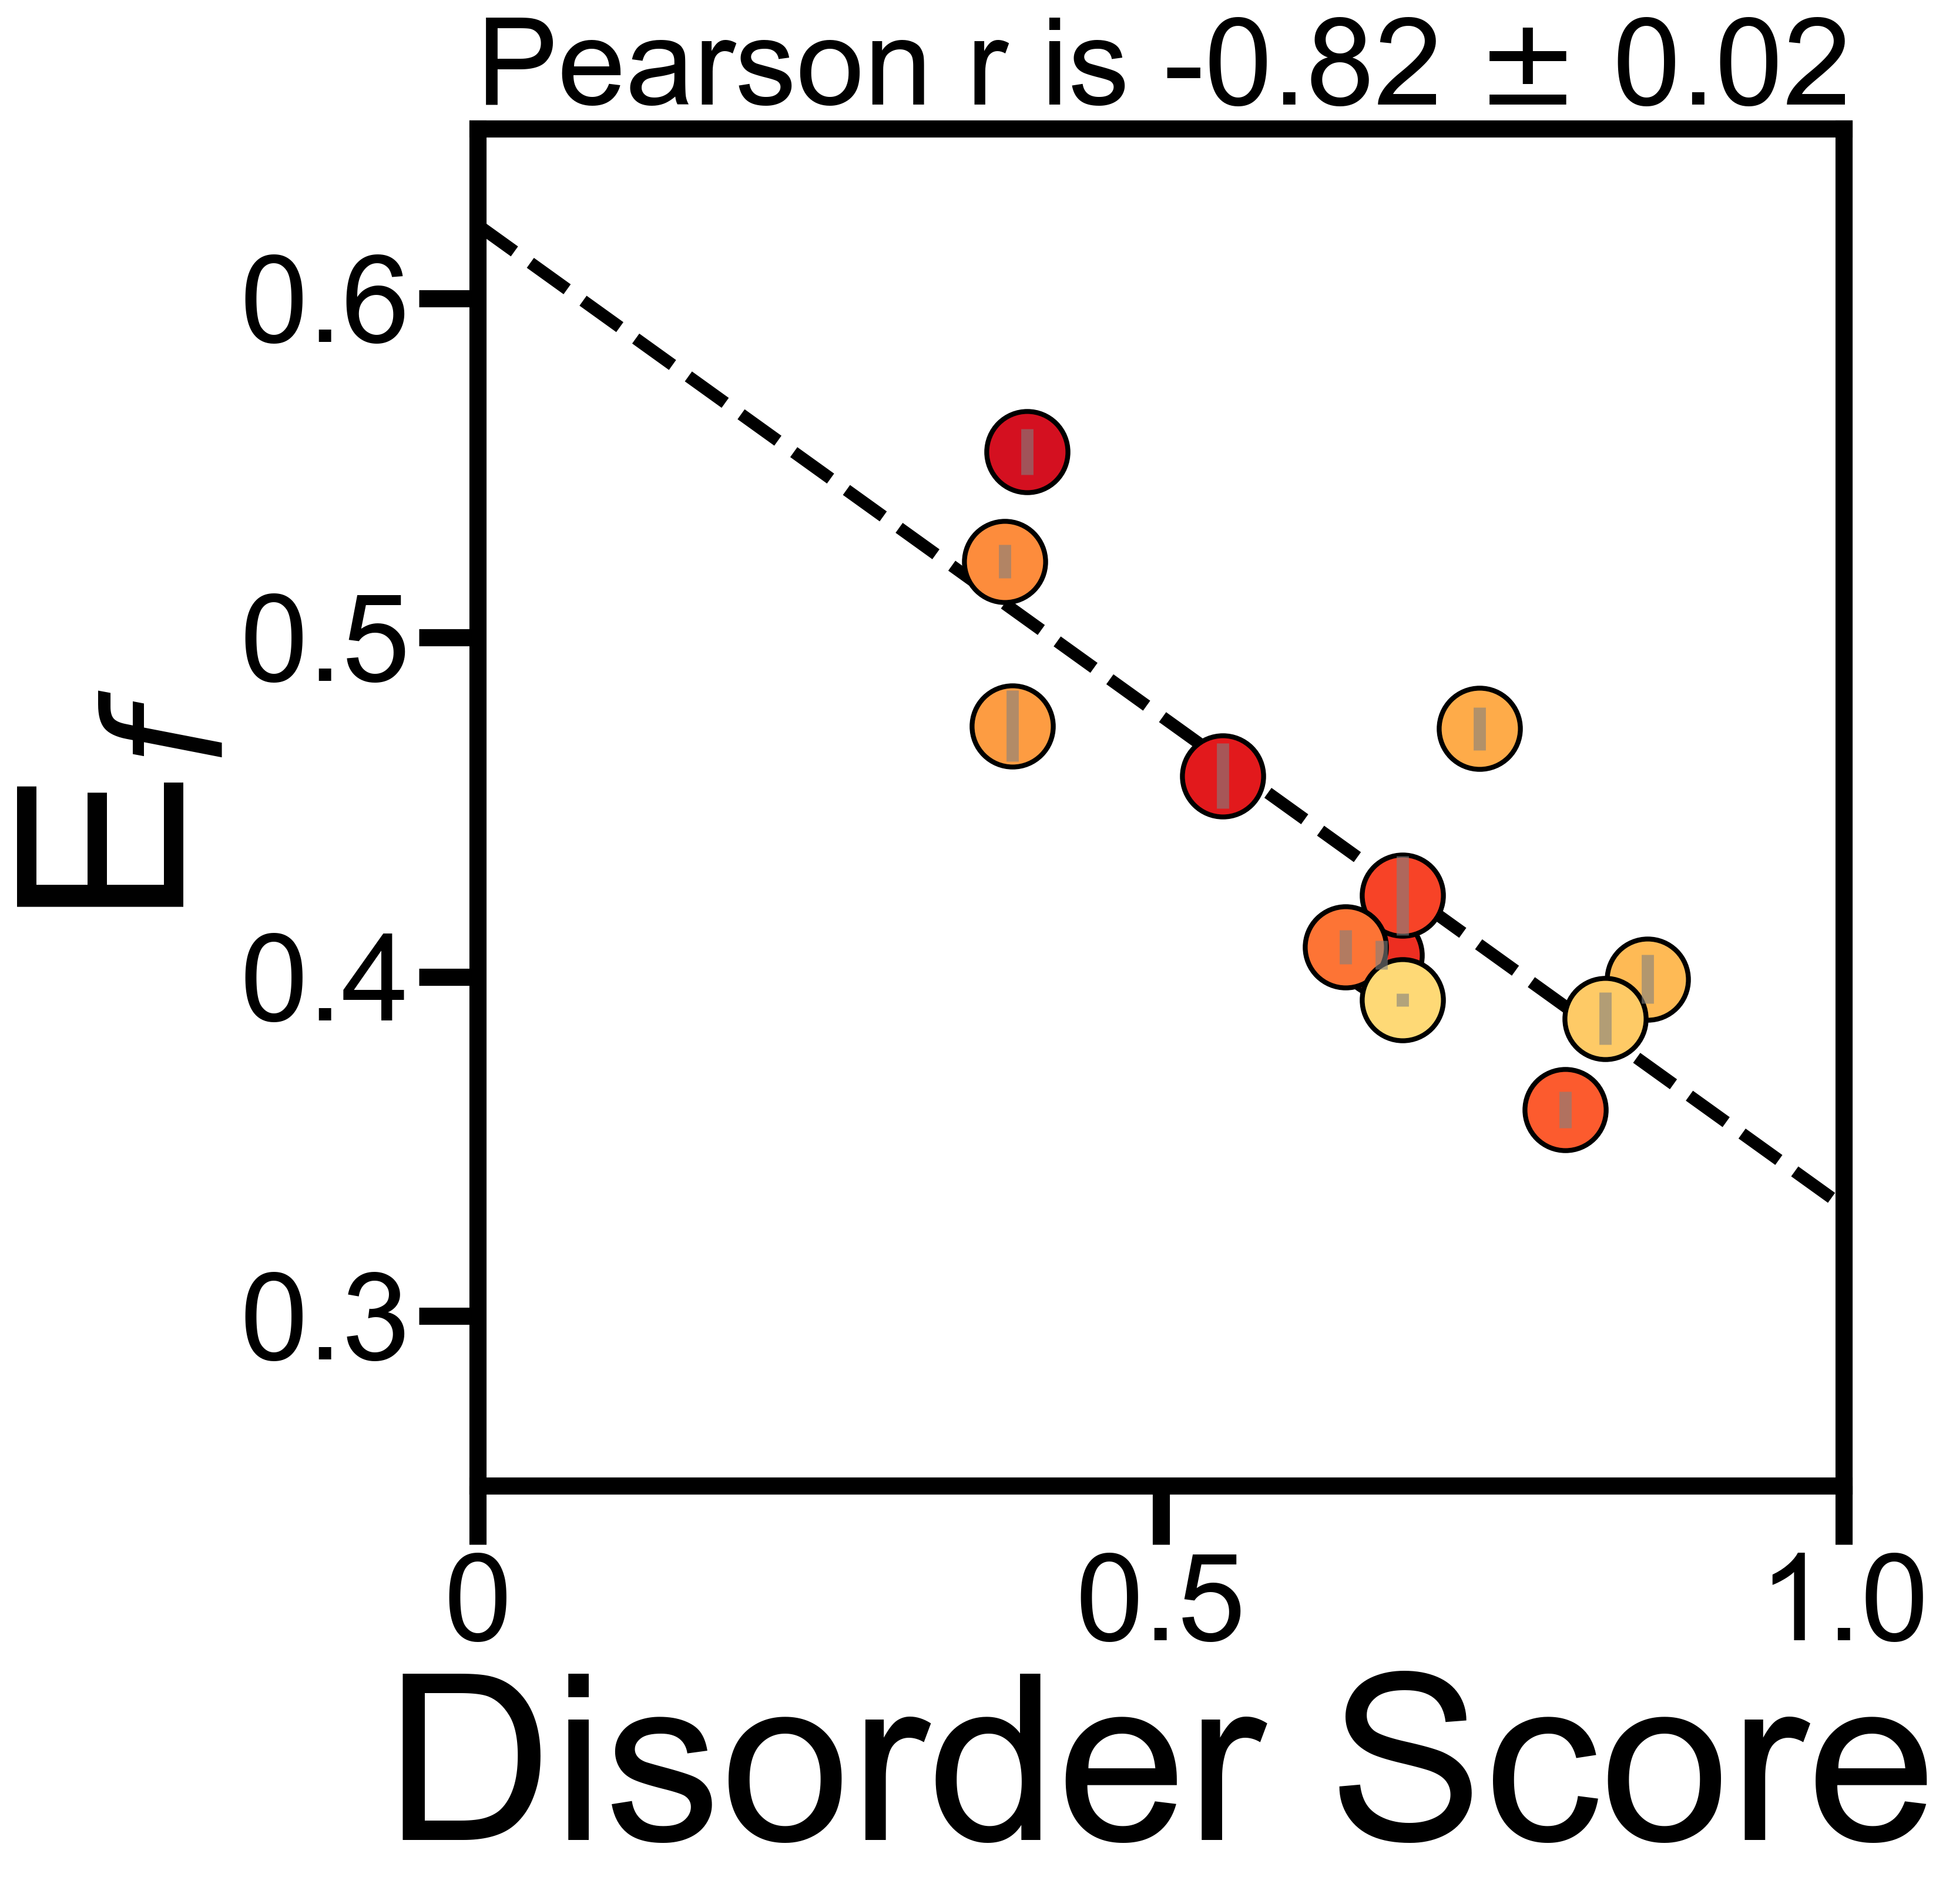

In [74]:
median_r = np.median(rho_sim)
std_r = np.std(rho_sim)

N=12
plt.rcParams["axes.prop_cycle"] = plt.cycler("color", plt.cm.YlOrRd(np.linspace(0.8, 0.25, N)))

x= correlation
x_err = correlation_error
y= center
y_err = y_error
x_label = 'Disorder Score'

fig, ax  = plt.subplots(figsize=(10, 10))
mpl.rcParams['figure.dpi'] = 300
res = stats.linregress(x, y)
ax.set_xlim([0,1])
ax.set_ylim([0.25,0.65])
temp_x = np.array([0, 1])
ax.plot(temp_x, res.intercept + res.slope*temp_x, 'k--', linewidth=5)
for i, b, xe, ye in zip(x, y, x_err, y_err):
    ax.scatter(x=i, y=b, edgecolors='k', s=1100, zorder=3, linewidths=2) 
    ax.errorbar(x=i, y=b, yerr=ye, c='gray', alpha=0.6, linewidth=5, zorder=4)

r_squared = res.rvalue **2
ax.tick_params(axis='both', which='major', labelsize=23)
ax.set_title(f"Pearson r is {round_sig(median_r, 2)} $\pm$ {round_sig(std_r, 1)}", fontsize=50)

yticks = [0.3, 0.4, 0.5, 0.6]
xticks = [0, 0.5, 1.0]
#xticks = [0.0, 0.6, 1.2]

ax.set_yticks(yticks)
ax.set_xticks(xticks)

tick_fontsize = 50
ax.set_yticklabels(yticks, fontsize=tick_fontsize)
ax.set_xticklabels(xticks, fontsize=tick_fontsize)

y_column = "E$_f$"
ax.set_ylabel(y_column, fontsize='xx-large')
ax.set_xlabel(x_label, fontsize='xx-large')

plt.savefig(r'Efret_comparison_to_disorder.svg' , format='svg', bbox_inches='tight')

In [54]:
x_err

array([0.27837771, 0.10735959, 0.15652071, 0.15471625, 0.07257239,
       0.16082939, 0.2780818 , 0.32692369, 0.21324681, 0.05747471,
       0.05855066, 0.17487084])

In [55]:
y_err

array([0.00678032, 0.00958945, 0.00418699, 0.01162995, 0.0053899 ,
       0.00501865, 0.00494966, 0.01054092, 0.00636368, 0.0071365 ,
       0.00771043, 0.00186596])